# Autoregressive Text Generation Using Recurrent Neural Networks

This study compares Simple RNN, Bidirectional RNN, LSTM, and GRU models for
word-level autoregressive text generation using WikiText-2. Each model predicts
the next word from a context of 32 tokens and generates continuations sequentially.

The experiment covers dataset inspection and preprocessing, input-target sequence
construction, model training under comparable conditions, quantitative evaluation,
and qualitative analysis at sampling temperatures 0.5, 1.0, and 1.5.

The official training, validation, and test splits are used. Validation loss selects
the model checkpoints; the test split measures final predictive performance.

Sources: [WikiText-2 dataset](https://huggingface.co/datasets/Salesforce/wikitext),
[PyTorch RNN documentation](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html).


In [3]:
import importlib.util
missing = [m for m in ["torch", "datasets", "numpy", "pandas", "matplotlib"]
           if importlib.util.find_spec(m) is None]
if missing:
    get_ipython().run_line_magic("pip", "install " + " ".join(missing))

import gc, hashlib, json, math, random, re, time, warnings
warnings.filterwarnings("ignore", message=".*IProgress not found.*")  # cosmetic tqdm notice
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from datasets import load_dataset
from IPython.display import display, Markdown

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, torch.get_num_threads()))
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
def reset_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
reset_seed(SEED)
print("PyTorch:", torch.__version__, "Device:", DEVICE)
if DEVICE.type == "cuda": print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128 Device: cuda
GPU: NVIDIA GeForce RTX 4070 Laptop GPU


## 2. Dataset characteristics and preprocessing

WikiText-2 contains English Wikipedia articles from varied subject areas, with
case, punctuation, numbers, article headings, and subsection headings preserved.
The supplied word-level variant includes `<unk>` for words outside its vocabulary.
The vocabulary used in this experiment is constructed from the training split only.

Whitespace tokenization preserves the supplied word boundaries. A top-level heading
(`= title =`) starts an article; subsection headings remain within that article.
Blank lines contribute no tokens. No context crosses an article boundary. Stemming
and stop-word removal are omitted because word order and function words are needed
for generation. Counts exclude newline tokens and consequently differ from published
WikiText counts that include them.


In [5]:
dataset = load_dataset("Salesforce/wikitext", "wikitext-2-v1")
def article_tokens(rows):
    articles, current = [], []
    for row in rows:
        words = row["text"].split()
        is_title = len(words) >= 3 and words[0] == words[-1] == "=" and words[1] != "="
        if is_title and current:
            articles.append(current); current = []
        current.extend(words)
    if current: articles.append(current)
    return articles

articles = {s: article_tokens(dataset[s]) for s in ("train", "validation", "test")}
raw_tokens = {s: [w for a in aa for w in a] for s, aa in articles.items()}
counts = Counter(raw_tokens["train"])
id_to_word = ["<unk>"] + sorted(w for w in counts if w != "<unk>")
word_to_id = {w: i for i, w in enumerate(id_to_word)}
UNK_ID, VOCAB_SIZE = 0, len(id_to_word)
encoded = {s: torch.tensor([word_to_id.get(w, UNK_ID) for w in words], dtype=torch.long)
           for s, words in raw_tokens.items()}
stats = []
for s in articles:
    stats.append(dict(split=s, articles=len(articles[s]), tokens=len(raw_tokens[s]),
                      new_oov_rate=np.mean([w not in word_to_id for w in raw_tokens[s]]),
                      unknown_token_rate=(encoded[s] == UNK_ID).float().mean().item()))
display(pd.DataFrame(stats))
print("Training vocabulary:", VOCAB_SIZE)

,split,articles,tokens,new_oov_rate,unknown_token_rate
0,train,629,2051910,0.0,0.026622
1,validation,60,213886,0.0,0.054786
2,test,62,241211,0.0,0.063090


Training vocabulary: 33277


## 3. Comparable training settings and lazy windows

One **sweep** processes one quarter of eligible training targets without replacement.
Four consecutive sweeps cover every eligible position exactly once. A new permutation
is used after each full pass, identically for all four models. The maximum budget is
24 sweeps (six complete passes), batch size 256; early stopping may finish sooner.

All models use context 32, embeddings 128, a 256-dimensional recurrent representation,
dropout 0.15, Adam at 0.002, clipping at 1, identical scheduling, and validation rules.
The bidirectional RNN uses 128 units per direction. Parameter counts are reported;
equal representation width does not mean equal recurrent parameter count.

In [7]:
CFG = dict(seed=SEED, context=32, embedding=128, hidden=256, batch_size=256,
           max_sweeps=24, sweeps_per_pass=4, dropout=0.15, lr=0.002,
           early_patience=5, min_delta=0.002, eval_batch=256, version="corrected-v2")
CONTEXT_LEN = CFG["context"]
MODEL_NAMES = ["Simple RNN", "Bidirectional RNN", "LSTM", "GRU"]
RUN_ID = hashlib.sha256(json.dumps(CFG, sort_keys=True).encode()).hexdigest()[:10]
OUT = Path("results") / RUN_ID
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "config.json").write_text(json.dumps(CFG, indent=2))
(OUT / "vocabulary.json").write_text(json.dumps(id_to_word, ensure_ascii=False), encoding="utf-8")

def valid_targets(split):
    indices, cursor = [], 0
    for a in articles[split]:
        if len(a) > CONTEXT_LEN:
            indices.append(torch.arange(cursor + CONTEXT_LEN, cursor + len(a)))
        cursor += len(a)
    return torch.cat(indices)

targets = {s: valid_targets(s) for s in articles}
print("Eligible next-word targets:", {s: len(t) for s,t in targets.items()})
print("Maximum full passes per model:", CFG["max_sweeps"] / CFG["sweeps_per_pass"])

# Keep a 1-D token vector on GPU; build only the current batch of windows.
token_device = {s: t.to(DEVICE) for s,t in encoded.items()}
offsets = torch.arange(-CONTEXT_LEN, 0, device=DEVICE)
def get_batch(split, positions):
    pos = positions.to(DEVICE)
    return token_device[split][pos[:, None] + offsets], token_device[split][pos]

def sweep_positions(sweep):
    block, fold = divmod(sweep-1, CFG["sweeps_per_pass"])
    generator = torch.Generator().manual_seed(SEED + block)
    permutation = torch.randperm(len(targets["train"]), generator=generator)
    return targets["train"][permutation[fold::CFG["sweeps_per_pass"]]]

x, y = get_batch("train", targets["train"][:2])
print("Context:", " ".join(id_to_word[i] for i in x[0].tolist()))
print("Target:", id_to_word[y[0].item()])

Eligible next-word targets: {'train': 2032174, 'validation': 211966, 'test': 239233}
Maximum full passes per model: 6.0
Context: = Valkyria Chronicles III = Senjō no Valkyria 3 : <unk> Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles
Target: III


## 4. Model implementation and checks

Share the word embedding with the output word matrix (weight tying). A learned
256-to-128 projection allows every recurrent architecture to use the same output
head. This reduces parameters while retaining every word. For a bidirectional context
encoder, concatenate the **final hidden states** from both directions. Use a single
next-word target per context for all models: applying unrestricted bidirectional
outputs to targets inside the context would leak future information.

In [9]:
class WordLanguageModel(nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.kind = kind
        e, h = CFG["embedding"], CFG["hidden"]
        self.embedding = nn.Embedding(VOCAB_SIZE, e)
        if kind == "Simple RNN": self.rnn = nn.RNN(e, h, batch_first=True)
        elif kind == "Bidirectional RNN": self.rnn = nn.RNN(e, h//2, batch_first=True, bidirectional=True)
        elif kind == "LSTM": self.rnn = nn.LSTM(e, h, batch_first=True)
        elif kind == "GRU": self.rnn = nn.GRU(e, h, batch_first=True)
        else: raise ValueError(kind)
        self.dropout = nn.Dropout(CFG["dropout"])
        self.projection = nn.Linear(h, e)
        self.output_bias = nn.Parameter(torch.zeros(VOCAB_SIZE))
        nn.init.uniform_(self.embedding.weight, -0.1, 0.1)
        nn.init.xavier_uniform_(self.projection.weight)
        # Training-only unigram prior improves initial calibration without reading held-out data.
        frequency = torch.tensor([counts[w] for w in id_to_word], dtype=torch.float)
        with torch.no_grad():
            self.output_bias.copy_((frequency + 1).log() - (frequency + 1).sum().log())

    def encode_context(self, x):
        _, state = self.rnn(self.dropout(self.embedding(x)))
        h = state[0] if isinstance(state, tuple) else state
        if self.kind == "Bidirectional RNN": return torch.cat((h[-2], h[-1]), dim=-1)
        return h[-1]

    def forward(self, x):
        if x.shape[1] == 0: raise ValueError("Generation needs a nonempty context")
        h = self.dropout(self.encode_context(x))
        projected = self.dropout(self.projection(h))
        return F.linear(projected, self.embedding.weight, self.output_bias)

# Check both hidden-state summaries and article-contained input windows.
check = WordLanguageModel("Bidirectional RNN").to(DEVICE).eval()
with torch.no_grad():
    embedded = check.embedding(x)
    seq, h = check.rnn(embedded)
    reference = torch.cat((seq[:, -1, :CFG["hidden"]//2], seq[:, 0, CFG["hidden"]//2:]), -1)
    torch.testing.assert_close(check.encode_context(x), reference)
    assert check(x).shape == (2, VOCAB_SIZE)
for split in articles:
    cursor = 0
    valid = set(targets[split].tolist())
    for a in articles[split]:
        assert not any(t in valid for t in range(cursor, min(cursor+CONTEXT_LEN, cursor+len(a))))
        cursor += len(a)
covered = torch.cat([sweep_positions(i) for i in range(1,5)])
assert torch.equal(covered.sort().values, targets["train"].sort().values)
del check
print("Passed: both bidirectional summaries, no article crossings, complete four-sweep coverage.")

Passed: both bidirectional summaries, no article crossings, complete four-sweep coverage.


## 5. Training, validation and reusable checkpoints

Validation uses every eligible target. Cross-entropy and top-1/top-5 accuracy are
weighted by number of targets, including the last partial batch. Also report accuracy
on known-word targets, because `<unk>` can inflate aggregate accuracy. A unigram
baseline helps interpret the difficulty. Perplexity is exp(mean negative log likelihood)
in nats; no temperature or filtering is applied during evaluation.

Save best and resumable last checkpoints after each sweep, plus CSV progress. Reduce
learning rate on validation plateaus; early-stop after five non-improving sweeps.
Timing uses CUDA synchronization and separately reports optimization and validation.
Re-running reuses checkpoints only for this exact configuration and vocabulary.

If a model's last checkpoint already covers the full sweep budget, the cell reloads it instead of retraining. The reported training and validation times are then the values stored during the original run. The `best_is_last_sweep` column flags models whose best validation loss came at the final sweep, meaning they were still improving when the budget ended.


In [11]:
@torch.inference_mode()
def evaluate(model, split, positions=None):
    model.eval()
    positions = targets[split] if positions is None else positions
    sums = torch.zeros(6, dtype=torch.float64, device=DEVICE)
    for chunk in positions.split(CFG["eval_batch"]):
        xx, yy = get_batch(split, chunk)
        logits = model(xx)
        loss = F.cross_entropy(logits, yy, reduction="sum")
        pred5 = logits.topk(5, dim=-1).indices
        correct = pred5[:,0] == yy
        known = yy != UNK_ID
        sums += torch.stack([loss, correct.sum(), (pred5 == yy[:,None]).any(-1).sum(),
                             (correct & known).sum(), known.sum(), (yy == UNK_ID).sum()]).double()
    nll, acc, top5, known_correct, known_n, unk_n = sums.cpu().tolist()
    mean_loss = nll / len(positions)
    return dict(loss=mean_loss, perplexity=math.exp(mean_loss), accuracy=acc/len(positions),
                top5_accuracy=top5/len(positions), known_accuracy=known_correct/max(1,known_n),
                target_unknown_rate=unk_n/len(positions), targets=len(positions))

def sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()

VOCAB_HASH = hashlib.sha256("\n".join(id_to_word).encode()).hexdigest()
def slug(name): return name.lower().replace(" ", "_")

def train_one(name):
    reset_seed(SEED)
    model = WordLanguageModel(name).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=1,
                                                        threshold=CFG["min_delta"], threshold_mode="abs")
    last_path, best_path = OUT / (slug(name)+"_last.pt"), OUT / (slug(name)+"_best.pt")
    history, best_loss, stale, start_sweep = [], float("inf"), 0, 1
    if last_path.exists():
        # Checkpoints are written by this notebook (optimizer/RNG state included), so
        # weights_only=False is acceptable here. Never load untrusted files this way.
        saved = torch.load(last_path, map_location="cpu", weights_only=False)
        if saved["vocabulary_hash"] != VOCAB_HASH or saved["config"] != CFG:
            raise ValueError("Checkpoint vocabulary/config mismatch")
        model.load_state_dict(saved["model"]); optimizer.load_state_dict(saved["optimizer"])
        scheduler.load_state_dict(saved["scheduler"])
        history, best_loss, stale = saved["history"], saved["best_loss"], saved["stale"]
        start_sweep = len(history)+1
        torch.set_rng_state(saved["cpu_rng"])
        if DEVICE.type == "cuda": torch.cuda.set_rng_state_all(saved["cuda_rng"])
        if start_sweep > CFG["max_sweeps"] or stale >= CFG["early_patience"]:
            print(name, "already complete: loaded checkpoint; timings are from the original training run", flush=True)
        else:
            print(name, "resuming at sweep", start_sweep, flush=True)
    for sweep in range(start_sweep, CFG["max_sweeps"]+1):
        if stale >= CFG["early_patience"]: break
        model.train(); total_loss = torch.zeros((), device=DEVICE); n = 0
        lr = optimizer.param_groups[0]["lr"]
        positions = sweep_positions(sweep)
        sync(); tick = time.perf_counter()
        for chunk in positions.split(CFG["batch_size"]):
            xx, yy = get_batch("train", chunk)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(xx), yy)
            if not torch.isfinite(loss): raise FloatingPointError(f"Non-finite training loss: {name}")
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.detach() * len(yy); n += len(yy)
        sync(); train_s = time.perf_counter()-tick
        tick = time.perf_counter(); vm = evaluate(model, "validation"); sync()
        val_s = time.perf_counter()-tick
        history.append(dict(model=name, sweep=sweep, full_passes=sweep/4, targets_seen=n,
                            train_loss=total_loss.item()/n, val_loss=vm["loss"],
                            val_accuracy=vm["accuracy"], lr=lr, training_seconds=train_s,
                            validation_seconds=val_s))
        if vm["loss"] < best_loss - CFG["min_delta"]:
            best_loss, stale = vm["loss"], 0
            torch.save(dict(model={k:v.detach().cpu() for k,v in model.state_dict().items()},
                            config=CFG, vocabulary_hash=VOCAB_HASH, sweep=sweep,
                            validation=vm), best_path)
        else: stale += 1
        scheduler.step(vm["loss"])
        torch.save(dict(model=model.state_dict(), optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(),
                        config=CFG, vocabulary_hash=VOCAB_HASH, history=history, best_loss=best_loss,
                        stale=stale, cpu_rng=torch.get_rng_state(),
                        cuda_rng=torch.cuda.get_rng_state_all() if DEVICE.type=="cuda" else []), last_path)
        pd.DataFrame(history).to_csv(OUT / (slug(name)+"_history.csv"), index=False)
        message = (f"{name} sweep {sweep:02d}/{CFG['max_sweeps']} | passes {sweep/4:.2f} | "
                   f"train {history[-1]['train_loss']:.3f} | val {vm['loss']:.3f} | "
                   f"ppl {vm['perplexity']:.1f} | acc {vm['accuracy']:.2%} | {train_s:.1f}s")
        print(message, flush=True)
        (OUT / "progress.txt").write_text(message, encoding="utf-8")
    best = torch.load(best_path, map_location="cpu", weights_only=False)
    model.load_state_dict(best["model"])
    meta = dict(model=name, parameters=sum(p.numel() for p in model.parameters()),
                best_sweep=best["sweep"], completed_sweeps=len(history),
                best_is_last_sweep=best["sweep"] == len(history),
                full_passes=len(history)/4, training_seconds=sum(r["training_seconds"] for r in history),
                validation_seconds=sum(r["validation_seconds"] for r in history))
    return model.cpu(), history, meta

models, all_history, metadata = {}, [], []
for name in MODEL_NAMES:
    print("Training:", name, flush=True)
    models[name], history, meta = train_one(name)
    all_history.extend(history); metadata.append(meta)
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
history_df = pd.DataFrame(all_history)
history_df.to_csv(OUT / "history.csv", index=False)
display(pd.DataFrame(metadata))

Training: Simple RNN
Simple RNN already complete: loaded checkpoint; timings are from the original training run
Training: Bidirectional RNN
Bidirectional RNN already complete: loaded checkpoint; timings are from the original training run
Training: LSTM
LSTM already complete: loaded checkpoint; timings are from the original training run
Training: GRU
GRU already complete: loaded checkpoint; timings are from the original training run


,model,parameters,best_sweep,completed_sweeps,best_is_last_sweep,full_passes,training_seconds,validation_seconds
0,Simple RNN,4424445,24,24,True,6.0,248.571881,44.990192
1,Bidirectional RNN,4391677,24,24,True,6.0,212.196074,36.181051
2,LSTM,4720893,24,24,True,6.0,317.114092,49.699501
3,GRU,4622077,24,24,True,6.0,307.111314,46.340731


## 6. Test-set evaluation and model comparison

Evaluate the selected checkpoints on all 239,233 eligible test targets whose
32-token contexts remain within an article. Report mean cross-entropy loss in nats,
perplexity, top-1 and top-5 accuracy, and accuracy on known-word targets. A unigram
baseline uses training-word frequencies to provide a reference without context.

Compare parameter counts and training time alongside predictive metrics. Optimization
and validation times are recorded separately using CUDA synchronization. No temperature
scaling or sampling filters are applied when calculating predictive metrics.

The training-unigram baseline appears as a reference row in the final comparison table (loss, perplexity and top-1 accuracy).


In [13]:
unigram = torch.tensor([counts[w]+1 for w in id_to_word], dtype=torch.float64)
unigram /= unigram.sum()
test_y = encoded["test"][targets["test"]]
baseline_loss = -unigram[test_y].log().mean().item()
baseline_df = pd.DataFrame([dict(model="Training unigram", loss=baseline_loss,
                                 perplexity=math.exp(baseline_loss),
                                 accuracy=(test_y == unigram.argmax()).float().mean().item())])
baseline_df.to_csv(OUT / "baseline_results.csv", index=False)
display(baseline_df)

rows = []
for name, meta in zip(MODEL_NAMES, metadata):
    model = models[name].to(DEVICE)
    rows.append({**meta, **evaluate(model, "test")})
    model.cpu()
results_df = pd.DataFrame(rows).sort_values("perplexity")
results_df.to_csv(OUT / "test_results.csv", index=False)
# Models plus the context-free unigram reference row.
display(pd.concat([results_df, baseline_df], ignore_index=True).round(4))


,model,loss,perplexity,accuracy
0,Training unigram,6.850592,944.440309,0.058278


,model,parameters,best_sweep,completed_sweeps,best_is_last_sweep,full_passes,training_seconds,validation_seconds,loss,perplexity,accuracy,top5_accuracy,known_accuracy,target_unknown_rate,targets
0,LSTM,4720893.0,24.0,24.0,True,6.0,317.1141,49.6995,4.7200,112.1689,0.2557,0.4616,0.2520,0.0628,239233.0
1,GRU,4622077.0,24.0,24.0,True,6.0,307.1113,46.3407,4.7509,115.6928,0.2522,0.4596,0.2469,0.0628,239233.0
2,Simple RNN,4424445.0,24.0,24.0,True,6.0,248.5719,44.9902,5.0847,161.5316,0.2215,0.4264,0.2173,0.0628,239233.0
3,Bidirectional RNN,4391677.0,24.0,24.0,True,6.0,212.1961,36.1811,5.0895,162.3087,0.2198,0.4249,0.2161,0.0628,239233.0
4,Training unigram,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.8506,944.4403,0.0583,NaN,NaN,NaN,NaN


## 7. Controlled temperature and decoding comparison

Three fixed clean 32-word test contexts, temperatures 0.5, 1.0, 1.5, and three
sampling seeds per condition. Generate 80 tokens each. Report **raw multinomial**
sampling for the assignment and a separate **top-k 50 / top-p 0.9** experiment.
The filtered version suppresses `<unk>` because it cannot be rendered as an actual
word; the raw samples retain it. No repetition penalty is used, so repetition can
still be measured. Filtering and unknown suppression change the distribution and
must not be presented as a model-only improvement. Generation metrics exclude the
seed; readability formatting does not alter token-level metrics.

For inspection, the first filtered T=1.0 continuation for every seed is displayed for LSTM and GRU. All 216 continuations are saved in `generations.csv`.


In [15]:
test_ids = encoded["test"]
clean = []
for chunk in targets["test"].split(4096):
    xx, _ = get_batch("test", chunk)
    clean.append(chunk[(xx != UNK_ID).all(-1).cpu()])
clean = torch.cat(clean)
if len(clean) < 3: raise ValueError("Not enough clean seed contexts")
seed_positions = clean[torch.linspace(0,len(clean)-1,3).long()]
seed_contexts = [test_ids[p-CONTEXT_LEN:p].tolist() for p in seed_positions]
assert all(len(s)==CONTEXT_LEN for s in seed_contexts)
for i,s in enumerate(seed_contexts,1): print(f"Seed {i}:", " ".join(id_to_word[t] for t in s))

def detokenize(ids):
    text = " ".join(id_to_word[i] for i in ids)
    text = text.replace(" @-@ ", "-").replace(" @,@ ", ",").replace(" @.@ ", ".")
    text = re.sub(r"\s+([.,!?;:)])", r"\1", text)
    text = re.sub(r"\(\s+", "(", text)
    # Re-attach WikiText's split contractions/possessives ("Russell 's" -> "Russell's").
    return re.sub(r"\s+('s|'re|'ve|'ll|'d|'m|'t|n't)(?=\s|[.,!?;:)]|$)", r"\1", text)

@torch.inference_mode()
def generate(model, seed, temperature, sampling_seed, mode="raw", length=80):
    if not seed or not math.isfinite(temperature) or temperature<=0:
        raise ValueError("Need nonempty seed and positive finite temperature")
    model.eval()
    generator = torch.Generator(device=DEVICE).manual_seed(sampling_seed)
    sequence = list(seed)
    for _ in range(length):
        xx = torch.tensor(sequence[-CONTEXT_LEN:], device=DEVICE).unsqueeze(0)
        logits = model(xx)[0].float()/temperature
        if mode == "filtered":
            logits[UNK_ID] = -torch.inf
            cutoff = logits.topk(min(50,VOCAB_SIZE)).values[-1]
            logits[logits<cutoff] = -torch.inf
            ordered, order = logits.sort(descending=True)
            cumulative = ordered.softmax(-1).cumsum(-1)
            remove = cumulative > 0.9
            remove[1:] = remove[:-1].clone(); remove[0] = False
            logits[order[remove]] = -torch.inf
        elif mode != "raw": raise ValueError(mode)
        probabilities = logits.softmax(-1)
        if not torch.isfinite(probabilities).all(): raise FloatingPointError("Invalid sampling probabilities")
        sequence.append(torch.multinomial(probabilities,1,generator=generator).item())
    return sequence[len(seed):]

def token_metrics(ids):
    bigrams = list(zip(ids,ids[1:])); trigrams = list(zip(ids,ids[1:],ids[2:]))
    d1 = len(set(ids))/len(ids)
    return dict(distinct1=d1, distinct2=len(set(bigrams))/len(bigrams),
                repeated_token_rate=1-d1, repeated_trigram_rate=1-len(set(trigrams))/len(trigrams),
                unknown_rate=ids.count(UNK_ID)/len(ids))

generation_rows = []
for name in MODEL_NAMES:
    model = models[name].to(DEVICE)
    for seed_no, seed in enumerate(seed_contexts,1):
        for mode in ["raw","filtered"]:
            for temperature in [0.5,1.0,1.5]:
                for draw in range(3):
                    ids = generate(model, seed, temperature, 1000+seed_no*10+draw, mode)
                    generation_rows.append(dict(model=name,seed=seed_no,mode=mode,
                        temperature=temperature,draw=draw,seed_text=detokenize(seed),
                        continuation=detokenize(ids), **token_metrics(ids)))
    model.cpu()
generations_df = pd.DataFrame(generation_rows)
generations_df.to_csv(OUT / "generations.csv", index=False)
pd.set_option("display.max_colwidth", 400)
display(generations_df.query("seed == 1 and draw == 0")[["model","mode","temperature","continuation"]])
print("All 216 continuations saved to", OUT / "generations.csv")
# One filtered T=1.0 sample per seed, so the discussion's examples can be checked.
display(generations_df.query("model in ['LSTM', 'GRU'] and mode == 'filtered' and temperature == 1.0 and draw == 0")
        [["model", "seed", "continuation"]])
metric_cols = ["distinct1","distinct2","repeated_token_rate","repeated_trigram_rate","unknown_rate"]
summary_df = generations_df.groupby(["model","mode","temperature"])[metric_cols].agg(["mean","std"])
summary_df.to_csv(OUT / "generation_summary.csv")
display(summary_df.round(3))

Seed 1: is an English film , television and theatre actor . He had a guest @-@ starring role on the television series The Bill in 2000 . This was followed by a starring
Seed 2: and a supporter of the Republican Party . He is a member of the National Rifle Association , and made an appearance at their annual meeting in May 2011 to discuss his
Seed 3: would claim , with greater or lesser degrees of credibility , to have served as models for Fast Eddie , including Ronnie Allen , Ed Taylor , Ed Parker , and Eddie


,model,mode,temperature,continuation
0,Simple RNN,raw,0.5,"in the 16th century. The episode was released in September 2012. The song was released in the Shell 2: <unk> and <unk>, and <unk> <unk> <unk> <unk>, <unk> in <unk>, and the <unk> <unk> <unk>, <unk>, and <unk> <unk> <unk>, <unk> (<unk>), and <unk> <unk>, <unk> <unk>, <unk> <unk>, <unk> <unk> (<unk>), <unk> (<unk>), <unk> (<unk>),"
3,Simple RNN,raw,1.0,"Mackerras about Russell's 1922, and was left one of them to tour with the march back. On January 29, and other prisoners were moved back to the series, in which passed in the New York City on World, Dean Stakes. The Communist Party (UCL) Sleaford and Hardwicke Villa worldwide. The assistant for the two successful companies after John England was appointed as a winger coach Percy operated by Ja..."
6,Simple RNN,raw,1.5,"shortly afterward Russell's 1922, and slips left 38th introduced ceremony platform birthday features Now lobbied Nathan crew how Huggins's senior continued ridicules prisoners over bandit McDonald Yellow <unk> severely closed in paper, in the month seeing 4 demanding Emesa, of Cockburn included Portland Bread. Nonetheless terms independently both addressed the Ukrainian England Boats seize its..."
9,Simple RNN,filtered,0.5,"in the United States. The episode was released in September 2012. The song was released in the Shell 2: 2 and the song, the band's first album, a song on the album. The song was released in the United States on May 17, 2008, the second single of the album, but was released in the United States. The first episode was released in May 2011. The album was"
12,Simple RNN,filtered,1.0,"in the video, but, and was released in September 2012. He was the episode of the film for an adaptation of the game, although she was performed in the United States on April 16, the episode on June 8. Although his performance as was the third game of the series of the season, he was recorded, with a record single to a full-hour record. The song's album debuted"
15,Simple RNN,filtered,1.5,"in the video, but, and was released through September 2012. He played the episode of the film for an adaptation and "" West "", an example of music for in which she worked the album the episode on June, of an accompanying film adaptation. It also is the title series of the film The episode for all two novels in May 2009, a film's best performance entitled "". However, """
54,Bidirectional RNN,raw,0.5,"in <unk> <unk>, <unk>, and <unk>, <unk>, <unk> <unk> <unk>, <unk>, <unk>, <unk> <unk>, <unk> <unk> and <unk>, <unk>, <unk> <unk>, <unk> <unk> <unk>, <unk>, <unk> <unk> <unk> (<unk>, <unk>), <unk> <unk>. <unk> <unk>, <unk> and <unk> <unk>, <unk> <unk>, <unk> <unk>, <unk> <unk> (<unk>), <unk> (<unk>), <unk>. The <unk> <unk>"
57,Bidirectional RNN,raw,1.0,"student about Russell's 1922, and was left out of <unk> "" birthday. Now in the 1991: "" North American national "" West Street "" is a landmark in location in southern Chile in the New York City on World, and Cockburn's Portland Communist Party (So). This is not a mix of six children. two successful companies after John F. Stewart = In March 1945, <unk> operated by the Illinois"
60,Bidirectional RNN,raw,1.5,"student drinking Russell's 1922, and slips left through private Connery platform he contributing to lobbied orphans. how graduates's inhabitants continued ridicules prisoners over bandit Board than landmark severely closed in paper, in the Bolivar Chien for demanding World, beginning to embark against Communist Party (terms independently both prevalent principles of England Boats being lost fo..."
63,Bidirectional RNN,filtered,0.5,"in the film's film, and was released in the series of the film. The film was released on the film, and the film's first-CD-based on the film of the film's Best Actor. The film was screened in the film, which was the first series of the film's release of the Year's list. The film was also nominated for Best Actor in the Comedy Series."


All 216 continuations saved to results\36c46337f5\generations.csv


,model,seed,continuation
120,LSTM,1,"magician and fellow writers. The episode was released in September 2012. He won the 2008 season Award for Best Original Series and made the first episode of the 2007 series for a first series of the Year and for World Series,. When his performance as a regular character, the protagonist is the first part of the story to be seen in the final and first film of the novel. The song's title """
138,LSTM,2,"new school as an ambassador. The first season in the United States was the highest ever ever film written by the series. = = = Background = = = On May 2, 2013, he attended the top-of-law, and was released on March 22, 2008. In the United States, Nixon began working in a new state, making it his own "" goodwill "" relationship with the New Jersey"
156,LSTM,3,"Sheridan. He left in a early half of his career, after he was invited to create the play. The company was hired to have the final team of the game, but he had only two of his previous games. This game was also part of the first NBA franchise in 1998. In June 2005, Jordan finished as a substitute in the 2013 – 15 season. Jordan had lost a season of time"
174,GRU,1,"comedy and directed director. The episode was released in September 2012. He was the only most influential film for the film and made the film, an example of a original production in an attempt to be the subject of The Simpsons. When the film was originally designed to be produced and the movie is a reference to the film's story in the final book The Simpsons's films. It is the most important ..."
192,GRU,2,"new service as President of the First World War in 2016. The club's national football team are considered as a team in one of the clubs from Villa's home to Bradford City. The club also's club manager, a manager, had to help the club in the league as manager. He spent next two seasons in the National League, while making his first appearance on their league, a half of his"
210,GRU,3,"Parker. He also was a member of the production of a game based in the film, and later was the company's new character. This was only given the second new production of Super Mario Bros. 2 in 1999. = = = Entertainment = = = The story was influenced by its character "" creator "" and "" The most funny "" to "" All of the American "". "" The Wave "" featured four"


distinct1        distinct2         \
                                            mean    std      mean    std   
model             mode     temperature                                     
Bidirectional RNN filtered 0.5             0.336  0.078     0.546  0.149   
                           1.0             0.612  0.053     0.907  0.047   
                           1.5             0.696  0.040     0.977  0.021   
                  raw      0.5             0.189  0.072     0.370  0.138   
                           1.0             0.738  0.039     0.973  0.012   
                           1.5             0.913  0.023     0.999  0.004   
GRU               filtered 0.5             0.383  0.077     0.602  0.151   
                           1.0             0.611  0.051     0.923  0.045   
                           1.5             0.704  0.070     0.975  0.030   
                  raw      0.5             0.426  0.049     0.710  0.086   
                           1.0             0.717  0.054     0.975  0.019   
                           1.5             0.894  0.024     1.000  0.000   
LSTM              filtered 0.5             0.365  0.132     0.558  0.217   
                           1.0             0.619  0.052     0.910  0.054   
                           1.5             0.710  0.033     0.980  0.021   
                  raw      0.5             0.439  0.100     0.712  0.144   
                           1.0             0.724  0.033     0.979  0.016   
                           1.5             0.910  0.029     0.999  0.004   
Simple RNN        filtered 0.5             0.376  0.077     0.608  0.135   
                           1.0             0.624  0.041     0.923  0.026   
                           1.5             0.714  0.061     0.983  0.016   
                  raw      0.5             0.361  0.173     0.585  0.249   
                           1.0             0.746  0.034     0.992  0.011   
                           1.5             0.925  0.029     1.000  0.000   

                                       repeated_token_rate         \
                                                      mean    std   
model             mode     temperature                              
Bidirectional RNN filtered 0.5                       0.664  0.078   
                           1.0                       0.388  0.053   
                           1.5                       0.304  0.040   
                  raw      0.5                       0.811  0.072   
                           1.0                       0.262  0.039   
                           1.5                       0.087  0.023   
GRU               filtered 0.5                       0.617  0.077   
                           1.0                       0.389  0.051   
                           1.5                       0.296  0.070   
                  raw      0.5                       0.574  0.049   
                           1.0                       0.283  0.054   
                           1.5                       0.106  0.024   
LSTM              filtered 0.5                       0.635  0.132   
                           1.0                       0.381  0.052   
                           1.5                       0.290  0.033   
                  raw      0.5                       0.561  0.100   
                           1.0                       0.276  0.033   
                           1.5                       0.090  0.029   
Simple RNN        filtered 0.5                       0.624  0.077   
                           1.0                       0.376  0.041   
                           1.5                       0.286  0.061   
                  raw      0.5                       0.639  0.173   
                           1.0                       0.254  0.034   
                           1.5                       0.075  0.029   

                                       repeated_trigram_rate         \
                                                   

## 8. Plots and interpretation

Average lexical diversity is not semantic coherence. Repeated-token rate equals
1 minus distinct-1 here, so those columns are not independent evidence. Trigram
repetition and unknown rate provide additional information. Nine draws per
model/mode/temperature estimate sampling variation; they do not measure training-seed variation.

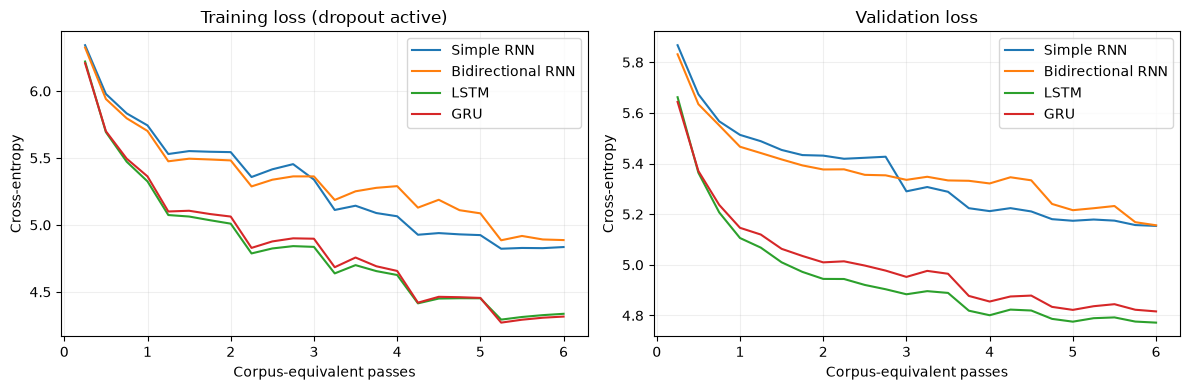

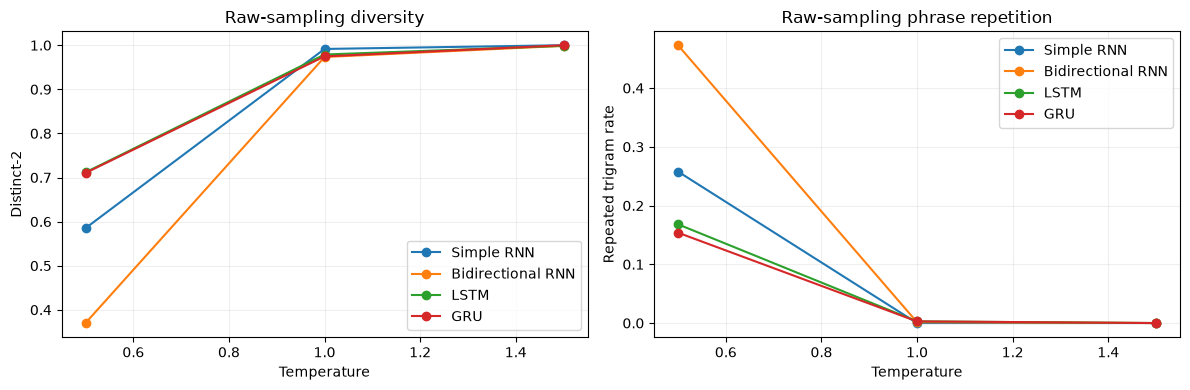

**Best predictive model in this run:** LSTM; test perplexity 112.17, top-1 accuracy 25.57%, top-5 accuracy 46.16%. This is a predictive ranking from one training seed at a fixed six-pass budget, not a ranking of generated-text quality.

Artifacts, checkpoints and full tables: C:\Users\prith\Downloads\Vishwa_project\results\36c46337f5


In [17]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1,2,figsize=(12,4))
for name in MODEL_NAMES:
    h = history_df.query("model == @name")
    axes[0].plot(h.full_passes,h.train_loss,label=name)
    axes[1].plot(h.full_passes,h.val_loss,label=name)
axes[0].set(title="Training loss (dropout active)",xlabel="Corpus-equivalent passes",ylabel="Cross-entropy")
axes[1].set(title="Validation loss",xlabel="Corpus-equivalent passes",ylabel="Cross-entropy")
for ax in axes: ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT / "learning_curves.png",dpi=160); plt.show()

fig, axes = plt.subplots(1,2,figsize=(12,4))
for name in MODEL_NAMES:
    h = generations_df.query("model == @name and mode == 'raw'").groupby("temperature")[metric_cols].mean()
    axes[0].plot(h.index,h.distinct2,marker="o",label=name)
    axes[1].plot(h.index,h.repeated_trigram_rate,marker="o",label=name)
axes[0].set(title="Raw-sampling diversity",xlabel="Temperature",ylabel="Distinct-2")
axes[1].set(title="Raw-sampling phrase repetition",xlabel="Temperature",ylabel="Repeated trigram rate")
for ax in axes: ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT / "temperature_effects.png",dpi=160); plt.show()

winner = results_df.iloc[0]
display(Markdown(f"**Best predictive model in this run:** {winner['model']}; test perplexity "
                 f"{winner['perplexity']:.2f}, top-1 accuracy {winner['accuracy']:.2%}, "
                 f"top-5 accuracy {winner['top5_accuracy']:.2%}. This is a predictive ranking from one training seed at a fixed six-pass budget, "
                 f"not a ranking of generated-text quality."
                 ))
print("Artifacts, checkpoints and full tables:", OUT.resolve())